# Soluzioni — Lezione 8: Modelli di lingua e progetto
[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/solutions/08_modelli_di_lingua_progetto_soluzioni.ipynb)

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
import math
import random
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def leggi_testo(nome):
    righe = (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines()
    return "\n".join(r for r in righe if not r.startswith("#"))

def tokenizza(testo):
    """Parole e segni di punteggiatura, in minuscolo: 'Che gioia!' → ['che', 'gioia', '!']"""
    return re.findall(r"\w+|[^\w\s]", testo.lower())

def ricomponi(tokens):
    testo = " ".join(tokens)
    testo = re.sub(r" ([,.;:!?»)])", r"\1", testo)
    return re.sub(r"([«(]) ", r"\1", testo)

OPERE = {"Collodi": "collodi_pinocchio.txt", "Manzoni": "manzoni_promessi_sposi.txt", "Dante": "dante_commedia.txt",
         "Leopardi": "leopardi_canti.txt", "Deledda": "deledda_dopo_il_divorzio.txt",
         "Pirandello": "pirandello_cavallo_nella_luna.txt", "Di Giacomo": "digiacomo_novelle_napolitane.txt"}
TOKENS = {autore: tokenizza(leggi_testo(f)) for autore, f in OPERE.items()}
for a, t in TOKENS.items():
    print(f"{a:>10}: {len(t):,} token")

   Collodi: 52,868 token
   Manzoni: 285,367 token
     Dante: 127,055 token
  Leopardi: 30,290 token
   Deledda: 73,906 token
Pirandello: 47,641 token
Di Giacomo: 84,104 token


In [3]:
def addestra(tokens, n=3):
    """Conta, per ogni contesto di n-1 parole, quali parole vengono dopo e quante volte."""
    conteggi = defaultdict(Counter)
    for i in range(len(tokens) - n + 1):
        contesto = tuple(tokens[i:i + n - 1])
        conteggi[contesto][tokens[i + n - 1]] += 1
    return conteggi

def prossima_parola(modelli, contesto):
    """Usa il contesto più lungo che il modello conosce (se non lo conosce, ne usa uno più corto)."""
    for m in modelli:                                 # modelli: dal più lungo al più corto
        k = len(next(iter(m)))                         # lunghezza del contesto di questo modello
        ctx = tuple(contesto[-k:]) if k else tuple()
        if ctx in m:
            return m[ctx]
    return None

def genera(autore, inizio, n=3, lunghezza=40, seme=0):
    random.seed(seme)
    modelli = [addestra(TOKENS[autore], k) for k in range(n, 0, -1)]
    testo = tokenizza(inizio)
    for _ in range(lunghezza):
        candidati = prossima_parola(modelli, testo)
        parole_, pesi = zip(*candidati.items())
        testo.append(random.choices(parole_, weights=pesi)[0])   # estrazione proporzionale ai conteggi
    return ricomponi(testo)

In [4]:
def copia_piu_lunga(generato, autore, massimo=25):
    gen, corpus = tokenizza(generato), TOKENS[autore]
    for L in range(min(massimo, len(gen)), 0, -1):
        visti = {tuple(corpus[i:i + L]) for i in range(len(corpus) - L + 1)}
        for i in range(len(gen) - L + 1):
            if tuple(gen[i:i + L]) in visti:
                return L, ricomponi(gen[i:i + L])
    return 0, ""

## Esercizio 1 — Generare e controllare

In [5]:
for n in [2, 3, 4]:
    testo = genera("Dante", "e quindi uscimmo", n=n, lunghezza=40, seme=7)
    L, pezzo = copia_piu_lunga(testo, "Dante")
    print(f"n={n} (copia più lunga: {L} token)\n{testo}\n")

n=2 (copia più lunga: 5 token)
e quindi uscimmo a l sol di vostra nominanza che più di sùbito dimando e da più che l ’ cor tristo ad acquisto, tirando, ch ’ aere vivo, mi dischiomi, di quel ch ’ aspetta, questa doglia



n=3 (copia più lunga: 10 token)
e quindi uscimmo a riveder la madre, tal mi fec ’ io mi volsi, come tu vedi ben com ’ ella gira; vedi che già li er ’ anco del mio maestro disse: «io ti dirò perché tal



n=4 (copia più lunga: 16 token)
e quindi uscimmo a riveder le belle stelle, quando ti gioverà dicere “ i ’ son fatta da dio, sua mercé, tale, che la vostra casa onora, grida i segnori e grida la contrada, sì che i



**Commento.** Con `n=2` il testo è originale ma sgrammaticato; con `n=4` è molto "dantesco" perché **ricopia** lunghi pezzi di
Commedia. "Suonare come l'autore" e "essere creativi" sono in tensione: un modello piccolo può essere fedele solo copiando.

## Esercizio 2 — Chi è meno sorpreso?

In [6]:
VOCAB_COMUNE = set().union(*[set(t) for t in TOKENS.values()])

class Bigrammi:
    """Modello di bigrammi con lisciatura 'add-k': nessuna parola ha probabilità zero."""
    def __init__(self, tokens, k=0.1):
        self.bi = Counter(zip(tokens, tokens[1:]))
        self.uni = Counter(tokens)
        self.k, self.V = k, len(VOCAB_COMUNE) + 1
    def prob(self, prec, parola):
        return (self.bi[(prec, parola)] + self.k) / (self.uni[prec] + self.k * self.V)
    def perplessita(self, testo):
        t = tokenizza(testo)
        logp = sum(math.log(self.prob(a, b)) for a, b in zip(t, t[1:]))
        return math.exp(-logp / max(len(t) - 1, 1))

In [7]:
modelli_bi = {a: Bigrammi(t) for a, t in TOKENS.items()}
mie = ["Il burattino corse dalla Fata e le disse che non avrebbe detto più bugie.",
       "Il curato, che aveva veduto i bravi, se ne tornò a casa pensando ai casi suoi.",
       "Dolce e chiara è la notte, e la luna riposa sopra i tetti.",
       "Ho mandato un messaggio al gruppo per organizzare la riunione di domani."]
tab = pd.DataFrame({a: [m.perplessita(f) for f in mie] for a, m in modelli_bi.items()}, index=[f[:40] for f in mie]).round(0)
tab["meno sorpreso"] = tab.idxmin(axis=1)
tab

,Collodi,Manzoni,Dante,Leopardi,Deledda,Pirandello,Di Giacomo,meno sorpreso
Il burattino corse dalla Fata e le disse,5760.0,5057.0,19387.0,20476.0,5602.0,11355.0,6031.0,Manzoni
"Il curato, che aveva veduto i bravi, se",4578.0,538.0,10566.0,15231.0,4022.0,6960.0,4569.0,Manzoni
"Dolce e chiara è la notte, e la luna rip",4158.0,2809.0,3164.0,2062.0,2622.0,3147.0,3390.0,Leopardi
Ho mandato un messaggio al gruppo per or,23602.0,20339.0,45933.0,42123.0,17329.0,43293.0,22195.0,Deledda


**Commento.** Spesso il modello meno sorpreso è quello atteso, ma non sempre: i modelli più grandi (Manzoni ha 5 volte più testo)
"conoscono" più coppie di parole e tendono a essere meno sorpresi da tutto. La frase moderna sorprende tutti: nessun autore
dell'Ottocento parlava di *messaggi al gruppo*.

## Esercizio 3 — Un progetto svolto come esempio
- **Domanda:** la felicità lessicale cresce anche *dentro* il Paradiso, canto per canto, fino alla visione finale?
- **Dati:** i 33 canti del Paradiso (`commedia_canti.csv`); parole felici ogni 1000 (sei famiglie).
- **Metodo e baseline:** regressione lineare sul numero del canto; test di permutazione (baseline = ordine casuale dei canti).
- **Ipotesi:** sì, la letizia cresce avvicinandosi all'Empireo.
- **Esiti possibili:** cresce (ascesa anche lessicale); non cresce (la letizia è costante, o il lessico cambia: *luce*, *amore* invece
  di *letizia*); cresce per caso.
- **Interpretazione attesa e limiti:** le nostre 35 forme non coprono il lessico della luce e della visione, centrale negli ultimi canti.

Pendenza nel Paradiso: -0.047; mescolamenti con pendenza ≥ osservata: 94.0%


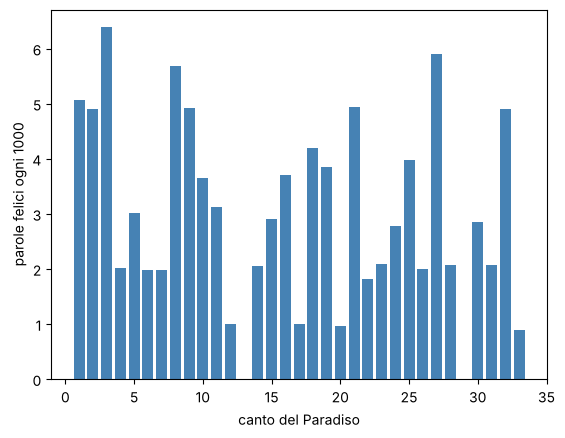

In [8]:
famiglie = pd.read_csv(DATI / "famiglie_felicita_it.csv")
FORME_FELICI = set(famiglie["forma"])
dc = pd.read_csv(DATI / "commedia_canti.csv")
par = dc[dc["cantica"] == "Paradiso"].reset_index(drop=True)
par["n"] = range(1, len(par) + 1)
par["felici_1000"] = par["testo"].apply(lambda t: (lambda w: sum(x in FORME_FELICI for x in w) / len(w) * 1000)(re.findall(r"\w+", t.lower())))

pend = np.polyfit(par["n"], par["felici_1000"], 1)[0]
rng = np.random.default_rng(0)
casuali = np.array([np.polyfit(par["n"], rng.permutation(par["felici_1000"]), 1)[0] for _ in range(1000)])
print(f"Pendenza nel Paradiso: {pend:+.3f}; mescolamenti con pendenza ≥ osservata: {np.mean(casuali >= pend):.1%}")
plt.bar(par["n"], par["felici_1000"], color="steelblue"); plt.xlabel("canto del Paradiso"); plt.ylabel("parole felici ogni 1000"); plt.show()

**Commento.** L'ipotesi è **smentita**: dentro il Paradiso la pendenza è leggermente negativa, e quasi tutti i mescolamenti
casuali fanno "meglio". La felicità *lessicale* misura sei famiglie di parole, mentre Dante, negli ultimi canti, dice la
beatitudine soprattutto con la **luce** e con l'**ineffabile**: il lessico della letizia lascia il posto a quello della visione. Un buon passo successivo:
ripetere l'analisi con una famiglia "luce" (*luce, lume, splendore, raggio…*) e confrontare le due curve.